In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import glob
import pyblock


# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

aa3_to_aa1 = {
    "Ala": "A",
    "Arg": "R",
    "Asn": "N",
    "Asp": "D",
    "Cys": "C",
    "Gln": "Q",
    "Glu": "E",
    "Gly": "G",
    "His": "H",
    "Ile": "I",
    "Leu": "L",
    "Lys": "K",
    "Met": "M",
    "Phe": "F",
    "Pro": "P",
    "Ser": "S",
    "Thr": "T",
    "Trp": "W",
    "Tyr": "Y",
    "Val": "V",
    "Pro_cis": "Pc"
}


tripeptides = ['Ala','Arg','Asn','Asp','Cys','Gln','Glu','Gly','His','Ile','Leu','Lys','Met','Phe','Ser','Thr','Trp','Tyr','Val']
base_path = "../AXA_peptides/"

In [2]:
cutoff_values = [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.25,1.50,1.75,2.0]
rho_front_types = ['rho_front_neigh', 'rho_front_neigh2', 'rho_front_neigh4']
angular_powers = [2.0, 4.0, 8.0]

df = pd.DataFrame()
df['cutoff'] = cutoff_values

for power, type in (zip(angular_powers, rho_front_types)):

    open_mu = []
    open_std = []

    for cutoff in cutoff_values:

        pop_open = []

        for aa in tripeptides:
            filepath = os.path.join(base_path, aa, "SIM", type, "rho_front_frames.npy")
            rho_front = np.load(filepath) # left, right
            S = rho_front[:,1]
                
            avg = np.mean(S)
            fopen = np.mean((S<cutoff)*1, axis=0)

            pop_open.append(fopen)
            
        open_mu.append(np.mean(pop_open))
        open_std.append(np.std(pop_open))

    df[f'power {power} fopen'] = open_mu
    df[f'power {power} fopen std'] = open_std

df.to_csv('angular_power_vs_cutoff_rho_front_fopen_r0_0_5nm_avg_AXA_peptides.csv')

df
            

        







,cutoff,power 2.0 fopen,power 2.0 fopen std,power 4.0 fopen,power 4.0 fopen std,power 8.0 fopen,power 8.0 fopen std
0,0.05,0.693661,0.066951,0.780442,0.056966,0.884916,0.037961
1,0.10,0.722780,0.064490,0.819899,0.050456,0.914660,0.031228
2,0.20,0.762535,0.059612,0.868164,0.041489,0.945802,0.022373
3,0.30,0.796020,0.054646,0.898832,0.035014,0.964897,0.015251
4,0.40,0.825568,0.049636,0.920387,0.029907,0.977859,0.009851
5,0.50,0.851327,0.044837,0.936541,0.025803,0.986702,0.006012
6,0.60,0.873012,0.040392,0.949433,0.021935,0.992451,0.003329
7,0.70,0.891260,0.036556,0.960213,0.018031,0.995896,0.001812
8,0.80,0.906827,0.033093,0.969416,0.014280,0.997844,0.000930
9,0.90,0.919981,0.030014,0.977237,0.010844,0.998952,0.000454


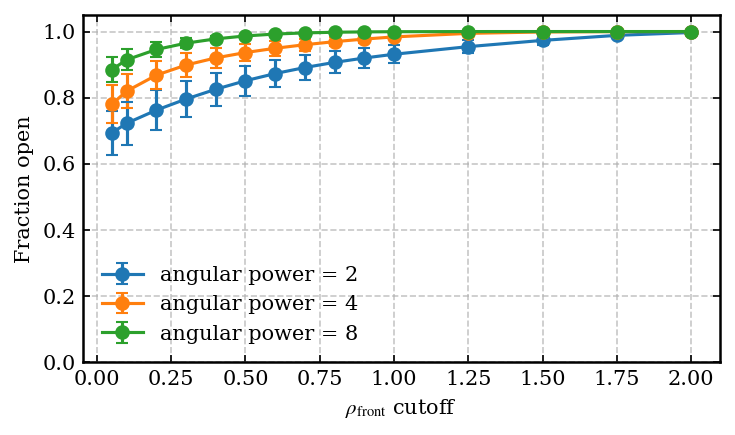

In [3]:


plt.figure(figsize=(5,3))

for power in angular_powers:
    y = df[f'power {power} fopen']
    yerr = df[f'power {power} fopen std']

    plt.errorbar(
        df['cutoff'],
        y,
        yerr=yerr,
        marker='o',
        capsize=3,
        linewidth=1.5,
        label=f'angular power = {power:g}'
    )

plt.xlabel(r'$\rho_\mathrm{front}$ cutoff')
plt.ylabel('Fraction open')
plt.xscale('linear')
plt.ylim(0, 1.05)
plt.legend(frameon=False)
plt.tight_layout()

plt.savefig('angular_power_vs_cutoff_rho_front_fopen_r0_0_5nm_avg_AXA_peptides.pdf', dpi=300)
plt.show()

In [4]:
threshold = 0.98

for power in angular_powers:
    col = f'power {power} fopen'

    above = df[df[col] > threshold]

    if len(above) > 0:
        first_cutoff = above.iloc[0]['cutoff']
        first_fopen = above.iloc[0][col]
        print(
            f'power {power:g}: first cutoff with average fopen > {threshold} '
            f'is {first_cutoff} (fopen = {first_fopen:.3f})'
        )
    else:
        print(f'power {power:g}: average fopen never exceeds {threshold}')

power 2: first cutoff with average fopen > 0.98 is 1.75 (fopen = 0.988)
power 4: first cutoff with average fopen > 0.98 is 1.0 (fopen = 0.984)
power 8: first cutoff with average fopen > 0.98 is 0.5 (fopen = 0.987)


In [5]:
threshold = 0.95

for power in angular_powers:
    col = f'power {power} fopen'

    above = df[df[col] > threshold]

    if len(above) > 0:
        first_cutoff = above.iloc[0]['cutoff']
        first_fopen = above.iloc[0][col]
        print(
            f'power {power:g}: first cutoff with average fopen > {threshold} '
            f'is {first_cutoff} (fopen = {first_fopen:.3f})'
        )
    else:
        print(f'power {power:g}: average fopen never exceeds {threshold}')

power 2: first cutoff with average fopen > 0.95 is 1.25 (fopen = 0.954)
power 4: first cutoff with average fopen > 0.95 is 0.7 (fopen = 0.960)
power 8: first cutoff with average fopen > 0.95 is 0.3 (fopen = 0.965)


In [6]:
# comparing angular power 8.0 no sidechain exclusions vs exclusion

cutoff_values = [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.25,1.50,1.75,2.0]
rho_front_types = ['rho_front_neigh4', 'rho_front_noexcl']
excl_type = ['excluded', 'all']

df = pd.DataFrame()
df['cutoff'] = cutoff_values

for type, dir in zip(excl_type, rho_front_types):

    open_mu = []
    open_std = []

    for cutoff in cutoff_values:

        pop_open = []

        for aa in tripeptides:
            filepath = os.path.join(base_path, aa, "SIM", dir, "rho_front_frames.npy")
            rho_front = np.load(filepath) # left, right
            S = rho_front[:,1]
                
            avg = np.mean(S)
            fopen = np.mean((S<cutoff)*1, axis=0)

            pop_open.append(fopen)
            
        open_mu.append(np.mean(pop_open))
        open_std.append(np.std(pop_open))

    df[f'{type} fopen'] = open_mu
    df[f'{type} fopen std'] = open_std

df.to_csv('SC_excl_vs_cutoff_rho_front_fopen_r0_0_5nm_pow8_avg_AXA_peptides.csv')

df
            

        







,cutoff,excluded fopen,excluded fopen std,all fopen,all fopen std
0,0.05,0.884916,0.037961,0.861073,0.062369
1,0.10,0.914660,0.031228,0.895070,0.054646
2,0.20,0.945802,0.022373,0.929115,0.045875
3,0.30,0.964897,0.015251,0.950100,0.038635
4,0.40,0.977859,0.009851,0.965127,0.032353
5,0.50,0.986702,0.006012,0.976123,0.026884
6,0.60,0.992451,0.003329,0.983867,0.022383
7,0.70,0.995896,0.001812,0.988995,0.019176
8,0.80,0.997844,0.000930,0.992181,0.016786
9,0.90,0.998952,0.000454,0.994187,0.015130


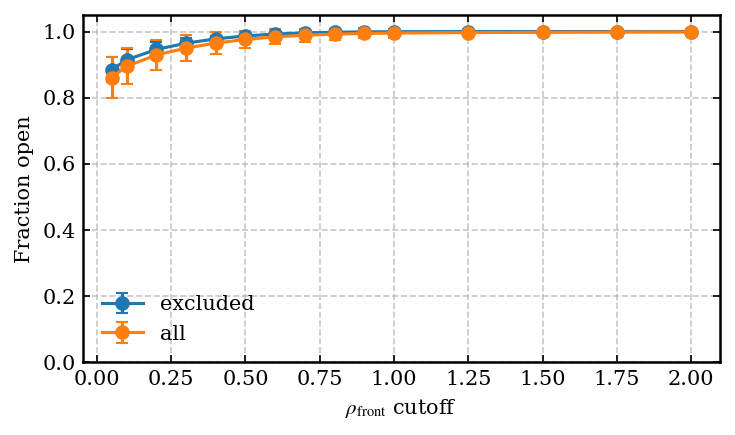

In [7]:


plt.figure(figsize=(5,3))

for type in excl_type:
    y = df[f'{type} fopen']
    yerr = df[f'{type} fopen std']

    plt.errorbar(
        df['cutoff'],
        y,
        yerr=yerr,
        marker='o',
        capsize=3,
        linewidth=1.5,
        label=f'{type}'
    )

plt.xlabel(r'$\rho_\mathrm{front}$ cutoff')
plt.ylabel('Fraction open')
plt.xscale('linear')
plt.ylim(0, 1.05)
plt.legend(frameon=False)
plt.tight_layout()

plt.savefig('SC_excl_vs_cutoff_rho_front_fopen_r0_0_5nm_pow8_avg_AXA_peptides.png', dpi=300)
plt.show()

In [8]:
# no exclusions effect of angular power

cutoff_values = [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.25,1.50,1.75,2.0]
rho_front_types = ['rho_front_noexcl3', 'rho_front_noexcl2', 'rho_front_noexcl']
angular_powers = [2.0, 4.0, 8.0]

df = pd.DataFrame()
df['cutoff'] = cutoff_values

for power, type in (zip(angular_powers, rho_front_types)):

    open_mu = []
    open_std = []

    for cutoff in cutoff_values:

        pop_open = []

        for aa in tripeptides:
            filepath = os.path.join(base_path, aa, "SIM", type, "rho_front_frames.npy")
            rho_front = np.load(filepath) # left, right
            S = rho_front[:,1]
                
            avg = np.mean(S)
            fopen = np.mean((S<cutoff)*1, axis=0)

            pop_open.append(fopen)
            
        open_mu.append(np.mean(pop_open))
        open_std.append(np.std(pop_open))

    df[f'power {power} fopen'] = open_mu
    df[f'power {power} fopen std'] = open_std

df.to_csv('angular_power_vs_cutoff_rho_front_noexcl_fopen_r0_0_5nm_avg_AXA_peptides.csv')

df
            

        







,cutoff,power 2.0 fopen,power 2.0 fopen std,power 4.0 fopen,power 4.0 fopen std,power 8.0 fopen,power 8.0 fopen std
0,0.05,0.506895,0.122034,0.713272,0.103511,0.861073,0.062369
1,0.10,0.587088,0.125733,0.770521,0.090028,0.895070,0.054646
2,0.20,0.665531,0.118903,0.832568,0.075079,0.929115,0.045875
3,0.30,0.715465,0.109383,0.869032,0.066674,0.950100,0.038635
4,0.40,0.755075,0.100384,0.893740,0.060980,0.965127,0.032353
5,0.50,0.787718,0.092869,0.911958,0.056557,0.976123,0.026884
6,0.60,0.815209,0.086395,0.926195,0.052895,0.983867,0.022383
7,0.70,0.838027,0.080997,0.938081,0.049436,0.988995,0.019176
8,0.80,0.857654,0.076482,0.948548,0.045795,0.992181,0.016786
9,0.90,0.874217,0.072438,0.957619,0.042198,0.994187,0.015130


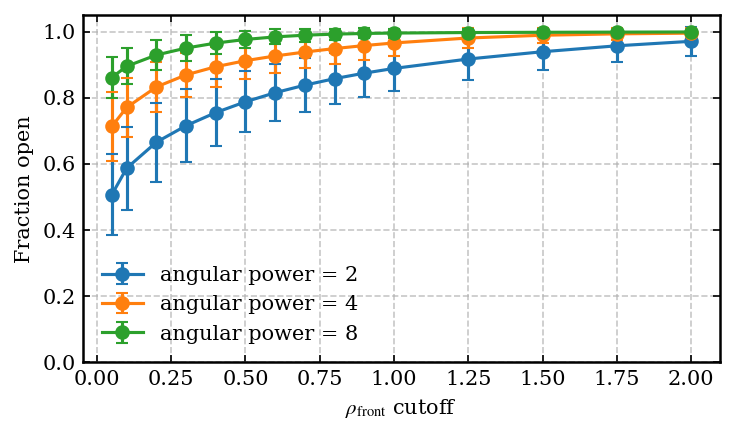

In [10]:


plt.figure(figsize=(5,3))

for power in angular_powers:
    y = df[f'power {power} fopen']
    yerr = df[f'power {power} fopen std']

    plt.errorbar(
        df['cutoff'],
        y,
        yerr=yerr,
        marker='o',
        capsize=3,
        linewidth=1.5,
        label=f'angular power = {power:g}'
    )

plt.xlabel(r'$\rho_\mathrm{front}$ cutoff')
plt.ylabel('Fraction open')
plt.xscale('linear')
plt.ylim(0, 1.05)
plt.legend(frameon=False)
plt.tight_layout()

plt.savefig('angular_power_vs_cutoff_rho_front_noexcl_fopen_r0_0_5nm_avg_AXA_peptides.pdf', dpi=300)
plt.show()